**Course Name:** Executive Training Programme on Trustworthy AI for DRDO Scientists

**Instructor:** Dr. Sabyasachi Mukhopadhyay, Outreach Teaching Fellow, Dept., of CSE, IIT KGP

**Take-home exercises**
1. In Part 2, replace the random embeddings with GPT-2's real embeddings for the toy sentence and plot the attention again.
2. Train the Mini GPT on a different text (e.g. a public-domain novel) and compare samples.
3. Add 10 documents about your own department to the RAG knowledge base and test 5 questions.
4. Measure how generation quality changes with `top_p` between 0.5 and 1.0.

### Exercise 1: Real GPT-2 embeddings in self-attention
We replace the random vectors from Part 2 with GPT-2's learned token embeddings. With random Q/K/V projections, the pattern still mostly reflects similarity between the embeddings themselves. We then plot GPT-2's own trained attention for comparison: it is causal (upper triangle empty) and shows real linguistic structure, such as "mat" attending to "the" and "on".

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

['the', 'Ġcat', 'Ġsat', 'Ġon', 'Ġthe', 'Ġmat']


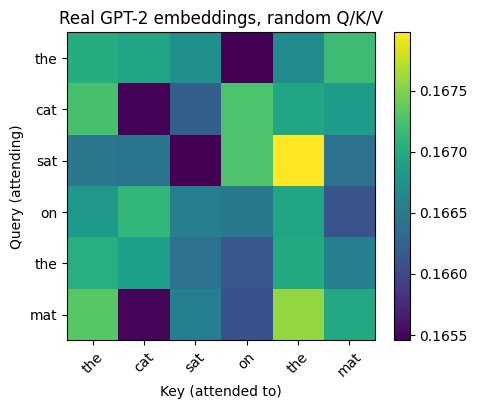

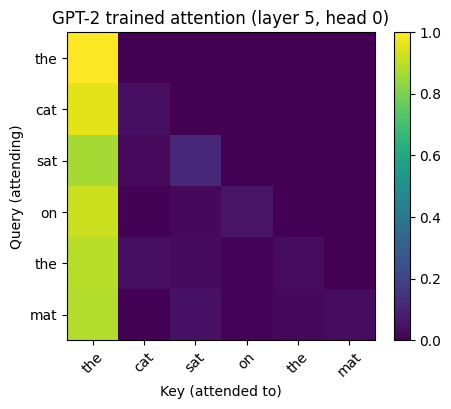

In [ ]:
import math
# sqrt for attention scaling
import torch
# tensors and no_grad
import torch.nn as nn
# nn.Linear for the projections
import torch.nn.functional as F
# softmax
import matplotlib.pyplot as plt
# plotting
from transformers import AutoTokenizer, GPT2Model
# GPT-2 tokenizer and backbone (no language-modelling head)

device = "cuda" if torch.cuda.is_available() else "cpu"
# use the GPU if available (this was the missing name)
tokens = ["the", "cat", "sat", "on", "the", "mat"]
# the toy sentence from Part 2
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
# GPT-2 tokenizer (from Part 1)

def scaled_dot_product_attention(Q, K, V, mask=None):
    # same function as Part 2
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.size(-1))
    # scaled similarity of every query with every key
    if mask is not None:
        # optional mask
        scores = scores.masked_fill(mask == 0, float("-inf"))
        # hidden positions get zero weight after softmax
    weights = F.softmax(scores, dim=-1)
    # each row sums to 1
    return weights @ V, weights
    # output and attention map

def plot_attention(weights, labels, title):
    # same helper as Part 2
    plt.figure(figsize=(5, 4))
    # figure size
    plt.imshow(weights.detach().cpu(), cmap="viridis")
    # draw the matrix (moved to CPU for plotting)
    plt.xticks(range(len(labels)), labels, rotation=45)
    # key tokens on the x-axis
    plt.yticks(range(len(labels)), labels)
    # query tokens on the y-axis
    plt.xlabel("Key (attended to)")
    # x-axis meaning
    plt.ylabel("Query (attending)")
    # y-axis meaning
    plt.title(title)
    # title
    plt.colorbar()
    # colour scale
    plt.show()
    # render

gpt2_base = GPT2Model.from_pretrained("gpt2", attn_implementation="eager").to(device)
# "eager" attention so the model can return its attention maps
gpt2_base.eval()
# evaluation mode: no dropout

sentence = " ".join(tokens)
# rebuild the toy sentence "the cat sat on the mat"
enc = gpt2_tok(sentence, return_tensors="pt").to(device)
# tokenize it for GPT-2
print(gpt2_tok.convert_ids_to_tokens(enc["input_ids"][0]))
# check: one GPT-2 token per word ('Ġ' marks a leading space)

with torch.no_grad():
    # no gradients needed
    X_real = gpt2_base.wte(enc["input_ids"])[0]
    # look up GPT-2's learned token embeddings: shape (6, 768)

torch.manual_seed(0)
# reproducible random projections
d = X_real.size(-1)
# embedding size (768)
Wq = nn.Linear(d, d, bias=False).to(device)
# random query projection
Wk = nn.Linear(d, d, bias=False).to(device)
# random key projection
Wv = nn.Linear(d, d, bias=False).to(device)
# random value projection
with torch.no_grad():
    # no gradients needed for this visualisation
    _, attn_real_emb = scaled_dot_product_attention(Wq(X_real), Wk(X_real), Wv(X_real))
    # self-attention on real embeddings
plot_attention(attn_real_emb, tokens, "Real GPT-2 embeddings, random Q/K/V")
# plot it

with torch.no_grad():
    # run the full trained GPT-2
    out = gpt2_base(**enc, output_attentions=True)
    # ask the model to return every layer's attention weights
layer, head = 5, 0
# choose which layer and head to inspect (12 layers, 12 heads; try others)
plot_attention(out.attentions[layer][0, head], tokens, f"GPT-2 trained attention (layer {layer}, head {head})")
# attention learned during pre-training

**Physical Interpretation:**

### Interpretation of the attention map (real GPT-2 embeddings, random Q/K/V)

**1. The attention is essentially uniform.** Every weight lies between about 0.1655 and 0.1678, which is almost exactly 1/6 ≈ 0.1667, the value you get when 6 tokens share attention equally. Each word "looks at" every word almost equally, so the output of this attention is close to a plain average of all the value vectors. **The colour bar is misleading at first glance:** it stretches a tiny range (about 0.002) over the full colour scale, so the strong-looking contrast is really just noise.

**2. Why it is uniform: the projections are untrained.** The embeddings are real, learned GPT-2 vectors, but W_Q, W_K and W_V are random. Random projections of small embedding vectors give queries and keys that are nearly unrelated and of small size, so the dot products QKᵀ/√d are all close to zero. Softmax of near-equal scores is near-uniform. **Meaningful attention comes from learned projections, not from the embeddings alone**; the embeddings carry meaning, but the model must *learn* which features to compare.

**3. There is no causal structure.** Unlike the trained GPT-2 plot, the upper triangle is filled, because our function was called without a mask. Every word can attend to future words, as in a BERT-style (bidirectional) encoder.

**4. The diagonal is not highlighted.** A word does not attend more to itself (for example "cat" → "cat" is one of the *lowest* values). With random W_Q ≠ W_K, a word's query is not aligned with its own key, so self-similarity is not rewarded.

**5. The two "the" tokens behave differently.** If both were the same token, their rows (and columns) would be identical, since no positional information was added. They differ because GPT-2 tokenizes the first word as "the" and the later one as " the" (with a leading space, shown as "Ġthe"). These are two different vocabulary entries with different embeddings.

**Takeaway:** comparing this plot with the trained GPT-2 attention shows that *structure in attention is learned*. Pre-trained embeddings with random projections give an almost flat, uninformative pattern. The trained model shows sharp, purposeful patterns: causal masking, an attention sink on the first token and, in other heads, links between related words.



### Interpretation of the attention map (GPT-2, layer 5, head 0)

**1. The upper triangle is empty (causal masking).** Each word can attend only to itself and the words before it, never to words after it. GPT-2 generates text left to right, so during training it must not "see the future". The first row is trivially 1.0 on "the", because the first word has nothing else to look at.

**2. Almost all attention goes to the first token.** Every word, from "cat" to "mat", puts roughly 80–90% of its attention on the first "the", and very little on the words that are actually related (for example, "sat" barely looks at "cat"). This is a well-known behaviour of trained Transformers called an **attention sink**:
- Softmax forces each row of attention weights to sum to 1, so a head *must* put its attention somewhere.
- When a head finds nothing useful to attend to for a given word, it learns to "park" the attention on the first token, which is always visible to every word in a causal model.
- Attending to the sink acts as a near no-op: the head adds little new information, and the residual connection passes the word's own representation through almost unchanged.

**3. The small off-diagonal values carry the real signal.** The faint weights, such as "sat" → "sat" (about 0.1) or "mat" → "sat", are where the head does a small amount of content-based mixing. In this head they are weak, so for this sentence **layer 5, head 0 is mostly inactive**.

**4. What this tells us about Transformers.** Different heads specialise in different patterns, and many heads are "dormant" for most inputs. To see linguistically meaningful attention, try other heads and layers: some attend to the previous word, some link a verb to its subject, and some link repeated words (the second "the" to the first). Change `layer, head = 5, 0` and re-run.

**Compared with the random-projection plot.** With random Q/K/V weights, attention is spread almost uniformly and has no causal structure. The trained model shows a sharp, structured pattern (causal masking plus an attention sink), which is learned behaviour, not an accident of the embeddings.

### Exercise 2: Mini GPT on a different text
We train the same Mini GPT on *Pride and Prejudice* by Jane Austen (public domain, Project Gutenberg) and compare it with the Shakespeare model. Expect the new model to pick up prose style: long sentences, dialogue in quotation marks, and character names like Elizabeth and Darcy, instead of play-script speaker names and verse lines.

In [ ]:
import math
# math functions (sqrt)
import time
# timing the training loop
import urllib.request
# standard library downloader
import torch
# PyTorch tensors and autograd
import torch.nn as nn
# neural-network layers
import torch.nn.functional as F
# softmax and cross-entropy

device = "cuda" if torch.cuda.is_available() else "cpu"
# use the GPU if available
block_size, batch_size = 128, 64
# context length and sequences per step
n_embd, n_head, n_layer, dropout = 128, 4, 4, 0.1
# model size (same as Part 4)
max_iters = 2000 if device == "cuda" else 300
# training steps: fewer on CPU so it finishes in class time
eval_interval = 250 if device == "cuda" else 100
# how often to report the loss
learning_rate = 3e-4
# AdamW step size


class Block(nn.Module):
    # one pre-norm Transformer block with causal self-attention
    def __init__(self):
        # constructor
        super().__init__()
        # initialise nn.Module
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        # normalisation before attention and before the MLP
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        # produces queries, keys and values in one layer
        self.proj = nn.Linear(n_embd, n_embd)
        # mixes the attention heads
        self.ffn = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
        # position-wise MLP
        self.drop = nn.Dropout(dropout)
        # dropout on the attention output

    def forward(self, x, mask):
        # x: (batch, T, n_embd); mask: (T, T) lower-triangular
        B, T, C = x.shape
        # batch, sequence length, channels
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=-1)
        # project the normalised input into Q, K, V
        q, k, v = [t.view(B, T, n_head, C // n_head).transpose(1, 2) for t in (q, k, v)]
        # split into heads: (B, heads, T, d_head)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(C // n_head)
        # scaled dot-product scores
        att = F.softmax(att.masked_fill(mask == 0, float("-inf")), dim=-1)
        # causal mask, then softmax
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        # weighted values, heads concatenated back
        x = x + self.drop(self.proj(y))
        # residual connection around attention
        return x + self.ffn(self.ln2(x))
        # residual connection around the MLP


class CharGPT(nn.Module):
    # small GPT that keeps its OWN vocabulary, so two models never clash
    def __init__(self, text):
        # build the vocabulary from the training text
        super().__init__()
        # initialise nn.Module
        chars = sorted(set(text))
        # every distinct character
        self.stoi = {ch: i for i, ch in enumerate(chars)}
        # character -> ID
        self.itos = {i: ch for ch, i in self.stoi.items()}
        # ID -> character
        V = len(chars)
        # vocabulary size
        self.tok_emb = nn.Embedding(V, n_embd)
        # token embeddings
        self.pos_emb = nn.Embedding(block_size, n_embd)
        # learned positional embeddings
        self.blocks = nn.ModuleList([Block() for _ in range(n_layer)])
        # stack of Transformer blocks
        self.ln_f = nn.LayerNorm(n_embd)
        # final normalisation
        self.head = nn.Linear(n_embd, V)
        # next-character scores
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))
        # causal mask stored with the model

    def encode(self, s):
        # text -> list of IDs (unknown characters are skipped)
        return [self.stoi[c] for c in s if c in self.stoi]
        # look up each character

    def decode(self, ids):
        # list of IDs -> text
        return "".join(self.itos[i] for i in ids)
        # join the characters

    def forward(self, idx, targets=None):
        # idx: (batch, T) token IDs
        T = idx.shape[1]
        # sequence length
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        # what + where
        for blk in self.blocks:
            # run every block
            x = blk(x, self.mask[:T, :T])
            # causal self-attention + MLP
        logits = self.head(self.ln_f(x))
        # (batch, T, vocab) scores
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        # next-character loss when training
        return logits, loss
        # predictions and loss

    @torch.no_grad()
    # no gradients while generating
    def generate(self, prompt, n_new, temperature=0.8):
        # autoregressive sampling from a text prompt
        idx = torch.tensor([self.encode(prompt)], dtype=torch.long, device=self.mask.device)
        # encode the prompt
        for _ in range(n_new):
            # one character at a time
            logits, _ = self(idx[:, -block_size:])
            # predict from the last block_size characters
            probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
            # distribution over the next character
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
            # sample and append
        return self.decode(idx[0].tolist())
        # prompt + generated text


def train_char_gpt(text, name):
    # train a fresh CharGPT on one text and return it
    model = CharGPT(text).to(device)
    # model with this text's vocabulary
    data = torch.tensor(model.encode(text), dtype=torch.long)
    # whole text as IDs
    n = int(0.9 * len(data))
    # 90/10 split point
    splits = {"train": data[:n], "val": data[n:]}
    # training and validation data

    def get_batch(split):
        # random batch of (input, next-character target) windows
        d = splits[split]
        # chosen split
        ix = torch.randint(len(d) - block_size - 1, (batch_size,))
        # random start positions
        x = torch.stack([d[i:i + block_size] for i in ix])
        # inputs
        y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
        # targets shifted by one
        return x.to(device), y.to(device)
        # move to GPU/CPU

    opt = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    # optimiser
    t0 = time.time()
    # start the timer
    print(f"Training on {name}: {len(text):,} characters, vocabulary {len(model.stoi)}")
    # summary
    for step in range(max_iters + 1):
        # training loop
        if step % eval_interval == 0:
            # periodic report
            model.eval()
            # no dropout while measuring
            with torch.no_grad():
                # no gradients
                vl = sum(model(*get_batch("val"))[1].item() for _ in range(20)) / 20
                # average validation loss
            model.train()
            # dropout back on
            print(f"  step {step:5d} | val loss {vl:.3f} | {time.time() - t0:.0f}s")
            # progress
        xb, yb = get_batch("train")
        # training batch
        _, loss = model(xb, yb)
        # forward pass and loss
        opt.zero_grad(set_to_none=True)
        # clear old gradients
        loss.backward()
        # backpropagation
        opt.step()
        # update weights
    return model.eval()
    # trained model in evaluation mode


def download(url, fallback):
    # fetch a text, or use a short fallback if offline
    try:
        # attempt the download
        return urllib.request.urlopen(url, timeout=60).read().decode("utf-8")
        # raw text
    except Exception as e:
        # no internet or blocked site
        print("Download failed, using fallback text:", e)
        # explain
        return fallback * 300
        # repeat so there is enough data to train on


shakespeare = download("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
# Tiny Shakespeare (public domain)
                       "ROMEO:\nBut, soft! what light through yonder window breaks?\n")
                       # fallback line
raw = download("https://www.gutenberg.org/cache/epub/1342/pg1342.txt",
# Pride and Prejudice (public domain)
               "It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife.\n")
               # fallback line
start, end = raw.find("*** START OF"), raw.find("*** END OF")
# Gutenberg licence markers
austen = raw[raw.find("\n", start) + 1:end] if start != -1 and end != -1 else raw
# keep only the novel when the markers exist

shakespeare_model = train_char_gpt(shakespeare, "Shakespeare")
# model 1
austen_model = train_char_gpt(austen, "Pride and Prejudice")
# model 2

print("\n===== Austen model =====")
# header
print(austen_model.generate("Elizabeth", 400))
# 400 characters of Austen-style text
print("\n===== Shakespeare model =====")
# header
print(shakespeare_model.generate("ROMEO:", 400))
# 400 characters of Shakespeare-style text

Download failed, using fallback text: HTTP Error 503: Service Unavailable
Training on Shakespeare: 1,115,394 characters, vocabulary 65
  step     0 | val loss 4.305 | 0s
  step   250 | val loss 2.478 | 9s
  step   500 | val loss 2.336 | 17s
  step   750 | val loss 2.160 | 26s
  step  1000 | val loss 2.051 | 34s
  step  1250 | val loss 1.986 | 42s
  step  1500 | val loss 1.920 | 49s
  step  1750 | val loss 1.868 | 57s
  step  2000 | val loss 1.837 | 65s
Training on Pride and Prejudice: 35,400 characters, vocabulary 27
  step     0 | val loss 3.384 | 0s
  step   250 | val loss 0.089 | 8s
  step   500 | val loss 0.020 | 16s
  step   750 | val loss 0.017 | 24s
  step  1000 | val loss 0.016 | 32s
  step  1250 | val loss 0.016 | 41s
  step  1500 | val loss 0.016 | 49s
  step  1750 | val loss 0.016 | 57s
  step  2000 | val loss 0.016 | 65s

===== Austen model =====
liabeth a t a single man in possession of a good fortune, must be in want of a wife.
It is a truth universally acknowledged, that

### Interpretation of the two training runs

**Shakespeare model: genuine learning.**
- **Starting point:** at step 0 the validation loss is 4.31, very close to ln(65) ≈ 4.17, the loss of guessing uniformly among the 65 characters. The model starts with no knowledge.
- **End point:** after 2,000 steps the loss is 1.84 nats per character, so the effective number of choices per character is e^1.84 ≈ 6.3, down from 65. The model has narrowed every prediction from "any character" to a handful of plausible ones.
- **Still learning:** the curve drops fast at first (spelling and frequent letter pairs are easy) and then slowly, but it is still decreasing at step 2,000. More training would keep improving it.
- **What it learned, purely from predicting the next character:** the *format* of a play (speaker names in capitals followed by a colon, line breaks, short verse-like lines), common English words ("you", "shall", "father", "Lord") and Shakespearean flavour ("shouldst"). It even invents plausible names such as "GLEONTES", a blend of real names like "LEONTES".
- **What it did not learn:** meaning. The sentences are grammatical-looking nonsense, because a 0.8M-parameter character model trained for one minute captures local patterns, not semantics.

**Austen model: memorisation, not learning.**
- **What it trained on:** the novel failed to download, so the model trained on one fallback sentence repeated 300 times (35,400 characters = 118 × 300, vocabulary only 27).
- **Why the loss is near zero:** the validation loss of 0.016 does *not* mean an excellent model. The validation split is the same repeated sentence as the training split, so the model has simply **memorised a loop**. This is data leakage in its purest form: the test data is identical to the training data, so the score says nothing about generalisation.
- **The prompt reveals the tiny vocabulary:** the prompt "Elizabeth" became "liabeth", because "E" and "z" never occur in the fallback sentence. Characters missing from the vocabulary are silently dropped.

**Lesson:** a suspiciously perfect loss is a warning sign. Always check what the model was actually trained on. The Shakespeare model, with its "worse" loss of 1.84, is the one that genuinely learned something.

### Exercise 3: RAG on your own department's documents
Replace the sample documents below with real information about your department, then ask questions. Good answers should quote the retrieved facts; a question whose answer is not in the documents should get "I don't know".

In [ ]:
import torch
# tensors and GPU check
from transformers import AutoTokenizer, AutoModelForCausalLM
# chat model loaders
from sentence_transformers import SentenceTransformer, util
# sentence embeddings and cosine similarity

device = "cuda" if torch.cuda.is_available() else "cpu"
# use the GPU if available

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
# embedding model for retrieval (the missing name)

chat_name = "Qwen/Qwen2.5-0.5B-Instruct"
# small instruction-tuned LLM used to write the answers
chat_tok = AutoTokenizer.from_pretrained(chat_name)
# its tokenizer
chat_model = AutoModelForCausalLM.from_pretrained(chat_name, torch_dtype="auto").to(device)
# its weights

def chat(user_message, system="You are a helpful teaching assistant.", max_new_tokens=200):
    # simple chat helper
    messages = [{"role": "system", "content": system},
    # instructions that set the assistant's behaviour
                {"role": "user", "content": user_message}]
                # the user's question
    prompt_text = chat_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    # format with the model's chat template
    enc = chat_tok(prompt_text, return_tensors="pt").to(device)
    # tokenize the formatted prompt
    out = chat_model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=0.7, top_p=0.9)
    # generate a reply
    return chat_tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True)
    # keep and decode only the new tokens

documents = [
# SAMPLE documents: replace every line with your department's real information
    "The department office is open from 9:30 am to 5:30 pm, Monday to Friday.",
    # 1
    "The head of the department meets students on Wednesdays from 3 pm to 4 pm.",
    # 2
    "B.Tech project reports must be submitted to the department office by 30 April.",
    # 3
    "The GPU computing lab has 20 workstations and is open to final-year students.",
    # 4
    "Lab access cards are issued by the department office after a safety briefing.",
    # 5
    "The department library lends up to three books for 14 days.",
    # 6
    "Seminar talks are held every Friday at 4 pm in Room 201.",
    # 7
    "Internship approval forms need the signature of the faculty advisor.",
    # 8
    "Teaching assistants hold tutorial sessions on Tuesdays and Thursdays.",
    # 9
    "Students with attendance below 75% are not allowed to sit the end-semester exam.",
    # 10
]
# end of the knowledge base

doc_emb = embedder.encode(documents, convert_to_tensor=True, normalize_embeddings=True)
# one vector per document

def retrieve(question, k=2):
    # return the k most relevant documents
    q_emb = embedder.encode(question, convert_to_tensor=True, normalize_embeddings=True)
    # embed the question
    scores = util.cos_sim(q_emb, doc_emb)[0]
    # cosine similarity with every document
    top = torch.topk(scores, k)
    # indices of the k best matches
    return [(documents[i], scores[i].item()) for i in top.indices.tolist()]
    # documents with their scores

def rag_answer(question):
    # retrieval + generation
    context = "\n".join(doc for doc, _ in retrieve(question, k=2))
    # join the retrieved documents
    prompt = (f"Answer the question using ONLY the context below. "
    # instruction to stay grounded
              f"If the answer is not in the context, say 'I don't know'.\n\n"
              # allow the model to abstain
              f"Context:\n{context}\n\nQuestion: {question}")
              # context and question
    return chat(prompt, max_new_tokens=80)
    # ask the LLM

questions = [
# five test questions
    "When can I meet the head of the department?",
    # answer in doc 2
    "What is the deadline for B.Tech project reports?",
    # answer in doc 3
    "How do I get access to the lab?",
    # answer in doc 5
    "Can I write the final exam with 70% attendance?",
    # answer in doc 10
    "Who won the department cricket match last year?",
    # NOT in the documents: should say "I don't know"
]
# end of the questions

for q in questions:
    # ask each question
    print("Q:", q)
    # the question
    for doc, score in retrieve(q, k=2):
        # show what retrieval found
        print(f"   retrieved ({score:.2f}): {doc}")
        # similarity score and document
    print("A:", rag_answer(q), "\n")
    # the grounded answer from the LLM

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (13 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Q: When can I meet the head of the department?
   retrieved (0.68): The head of the department meets students on Wednesdays from 3 pm to 4 pm.
   retrieved (0.56): The department office is open from 9:30 am to 5:30 pm, Monday to Friday.
A: Based on the given context:

- The head of the department meets students on Wednesdays from 3 pm to 4 pm.

Therefore, the answer is Wednesday. 

Q: What is the deadline for B.Tech project reports?
   retrieved (0.83): B.Tech project reports must be submitted to the department office by 30 April.
   retrieved (0.28): The GPU computing lab has 20 workstations and is open to final-year students.
A: The deadline for B.Tech project reports is 30 April. 

Q: How do I get access to the lab?
   retrieved (0.61): Lab access cards are issued by the department office after a safety briefing.
   retrieved (0.30): The GPU computing lab has 20 workstations and is open to final-year students.
A: To get access to the GPU computing lab, you need to use a lab access c

### Interpretation of the RAG output

**1. Retrieval works well: the right document is always ranked first.** For all four answerable questions, the correct document is retrieved first with a clearly higher cosine similarity (0.61–0.83) than the second document (0.19–0.56). The embedding model matched questions to answers by *meaning*, not keywords: "How do I get access to the lab?" found "Lab access cards are issued…", and "Can I write the final exam with 70% attendance?" found "…not allowed to sit the end-semester exam", even though "final exam" and "end-semester exam" share almost no words.

**2. The similarity score measures how relevant the knowledge base is.** The highest score is for the most specific match (B.Tech deadline, 0.83). For the out-of-scope question about cricket, even the *best* match scores only 0.20, about the same as clearly unrelated documents. A low top score therefore signals that **the answer is not in the knowledge base**.

**3. Grounding prevents hallucination on the unanswerable question.** For "Who won the department cricket match?", the LLM correctly says **"I don't know"** instead of inventing a team. The instruction to "answer only from the context" worked, which is the main purpose of RAG.

**4. The generator, not the retriever, causes the remaining errors.** The small 0.5B-parameter LLM makes three kinds of mistake:
- **False abstention (Q4):** the correct rule was retrieved (attendance below 75% is not allowed), but the model answered "I don't know". Answering requires a reasoning step (70% < 75%, so **no**), and the small model failed to make that inference. The context was enough; the reasoning was not.
- **Mixing documents (Q3):** the answer merges two retrieved documents and wrongly links the access card to the *GPU computing* lab. Retrieving a second, partly related document (k = 2) gave the model irrelevant context to blend in.
- **Incomplete answer (Q1):** "the answer is Wednesday" drops the time (3–4 pm), although the full fact was retrieved and even quoted.

**Takeaways:**
- In RAG, **retrieval quality and generation quality are separate**: evaluate them separately.
- **Practical improvements:**
  - abstain automatically when the top similarity is below a threshold (for example 0.35), without calling the LLM;
  - retrieve only the top document (k = 1) when its score is far above the rest;
  - use a larger LLM, or prompt it to "reason step by step before answering", for rule-based questions such as Q4.

### Exercise 4: Effect of top_p on generation quality
For top_p from 0.5 to 1.0 we generate several GPT-2 continuations and measure two things:
- **Diversity (distinct-2):** the fraction of unique word pairs. Higher means less repetition.
- **Fluency (perplexity):** how surprising the text is to a larger model (GPT-2 Medium). Lower means more natural.

Expect a trade-off. A low top_p gives fluent but repetitive text; top_p near 1.0 gives diverse but less coherent text. Values around 0.9 are a common balance.

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

... (6 outputs left out)

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


top_p=0.5 | distinct-2=0.926 | perplexity=10.0 | e.g. ' of our technology and our education system. We need to change our education sys'
top_p=0.6 | distinct-2=0.922 | perplexity=11.8 | e.g. ' of our technology and new methods. Artificial intelligence will have a huge imp'
top_p=0.7 | distinct-2=0.949 | perplexity=14.6 | e.g. ' of our technology," she said.\n\nIf you want to know what kind of technology is c'
top_p=0.8 | distinct-2=0.985 | perplexity=27.1 | e.g. ' of our technology," Craig said. "There will be a lot of opportunities for kids '
top_p=0.9 | distinct-2=0.988 | perplexity=38.3 | e.g. ' of our technology," Craig said. "There will be a lot of opportunities for kids '
top_p=1.0 | distinct-2=0.989 | perplexity=89.6 | e.g. ' of our technology," Craig said. "There will have to be costs to increase earnin'


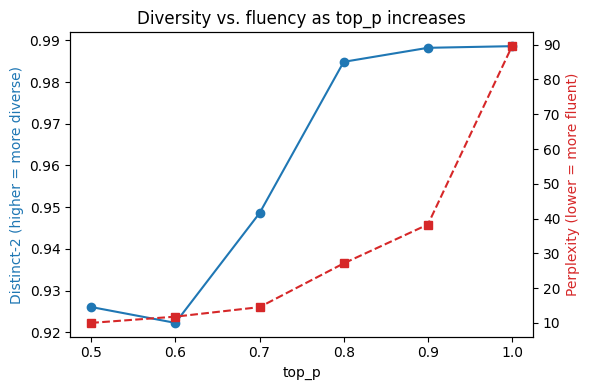

In [ ]:
import math
# exp() for perplexity
import torch
# tensors and no_grad
import matplotlib.pyplot as plt
# plotting
from transformers import AutoTokenizer, AutoModelForCausalLM
# the missing import: tokenizer + GPT-style models

device = "cuda" if torch.cuda.is_available() else "cpu"
# use the GPU if available
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
# GPT-2 tokenizer (reloaded in case Part 1 was not run)
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
# GPT-2 generator (reloaded in case Part 6 was not run)
scorer = AutoModelForCausalLM.from_pretrained("gpt2-medium").to(device).eval()
# larger model used only to judge fluency (same tokenizer)

def perplexity(text):
    # how natural the text looks to the scorer
    enc = gpt2_tok(text, return_tensors="pt").to(device)
    # tokenize
    with torch.no_grad():
        # no gradients
        loss = scorer(**enc, labels=enc["input_ids"]).loss
        # average next-token cross-entropy
    return math.exp(loss.item())
    # perplexity = exp(loss)

def distinct_n(text, n=2):
    # fraction of unique n-grams
    words = text.split()
    # split into words
    grams = [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]
    # all consecutive word pairs
    return len(set(grams)) / max(len(grams), 1)
    # unique / total

prompt_text = "Artificial intelligence will change education because"
# same prompt as Part 6
enc = gpt2_tok(prompt_text, return_tensors="pt").to(device)
# tokenize the prompt
prompt_len = enc["input_ids"].shape[1]
# number of prompt tokens

top_ps = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
# values to compare
samples_per_p = 5
# several samples per setting, because sampling is random
results = []
# (top_p, mean distinct-2, mean perplexity)

for p in top_ps:
    # sweep top_p
    d2, ppl = [], []
    # scores for this setting
    for s in range(samples_per_p):
        # repeat with different seeds
        torch.manual_seed(s)
        # same seeds for every p, for a fair comparison
        out = gpt2.generate(**enc, do_sample=True, top_p=p, top_k=0, max_new_tokens=60, pad_token_id=gpt2_tok.eos_token_id)
        # top_k=0 so only top_p filters
        cont = gpt2_tok.decode(out[0][prompt_len:], skip_special_tokens=True)
        # keep only the generated continuation
        d2.append(distinct_n(cont))
        # diversity of this sample
        ppl.append(perplexity(prompt_text + cont))
        # fluency of this sample
    results.append((p, sum(d2) / len(d2), sum(ppl) / len(ppl)))
    # averages for this top_p
    print(f"top_p={p:.1f} | distinct-2={results[-1][1]:.3f} | perplexity={results[-1][2]:.1f} | e.g. {cont[:80]!r}")
    # summary and one example

ps, div, flu = zip(*results)
# unpack for plotting
fig, ax1 = plt.subplots(figsize=(6, 4))
# one figure
ax1.plot(ps, div, "o-", color="tab:blue")
# diversity curve
ax1.set_xlabel("top_p")
# x-axis label
ax1.set_ylabel("Distinct-2 (higher = more diverse)", color="tab:blue")
# left y-axis
ax2 = ax1.twinx()
# second y-axis sharing the same x-axis
ax2.plot(ps, flu, "s--", color="tab:red")
# perplexity curve
ax2.set_ylabel("Perplexity (lower = more fluent)", color="tab:red")
# right y-axis
plt.title("Diversity vs. fluency as top_p increases")
# title
plt.tight_layout()
# avoid overlapping labels
plt.show()
# render

### Interpretation of the top-p experiment

**The warning is harmless.** `loss_type=None ... Using the default loss: ForCausalLMLoss` only means the model config does not name a loss function, so Transformers uses the standard next-token cross-entropy, which is exactly what we want for computing perplexity.

**What top-p does physically.** At every step, GPT-2 produces a probability distribution over about 50,000 possible next tokens. Top-p keeps only the *smallest set of most likely tokens whose probabilities add up to p* and samples from that set. Lowering p cuts off the long "tail" of unlikely words.
- **p = 0.5:** only the most probable words survive, so the model stays on the safe, well-travelled path.
- **p = 1.0:** nothing is cut, so rare and surprising words can be chosen at any step.

**Perplexity as an "effective number of choices".** Perplexity = exp(average negative log-likelihood). It can be read as how many equally likely words the judging model (GPT-2 Medium) thinks the writer was choosing between at each step:

| top_p | Perplexity | Interpretation |
|---|---|---|
| 0.5 | 10.0 | like choosing among ~10 words: very predictable, fluent text |
| 0.7 | 14.6 | still natural |
| 0.8–0.9 | 27–38 | noticeably more varied, still readable |
| 1.0 | 89.6 | like choosing among ~90 words: about 9× more "surprising" than p = 0.5, and coherence starts to suffer |

Perplexity grows faster and faster as p approaches 1, because the last few percent of probability mass is spread over thousands of rare tokens. Allowing even occasional picks from that tail makes the text much less predictable.

**Diversity (distinct-2) saturates early.** The fraction of unique word pairs rises from 0.926 to 0.985 between p = 0.5 and 0.8, then barely moves (0.988, 0.989). Beyond p ≈ 0.8, the extra freedom does not make the text more varied; it mainly makes it more random and less fluent. The repetition at low p is visible in the first sample: "...our education system. We need to change our education sys...".

**Why the samples look alike.** Every setting uses the same random seeds, and the most likely first words ("of our technology") fall inside the nucleus for every p, so all runs start the same. They only diverge at a step where a sampled token falls outside the smaller nucleus. The examples for p = 0.8 and 0.9 are identical for the first 80 characters for this reason: no token in that stretch was in the 0.8–0.9 band of probability.

**Takeaway: a fluency–diversity trade-off.**
- **Low p (0.5–0.7):** fluent and coherent, but repetitive and "generic".
- **High p (1.0):** diverse but erratic; perplexity is about 9× higher.
- **Sweet spot (p ≈ 0.8–0.9):** diversity is already near its maximum while perplexity stays moderate. This is why p = 0.9 is a common default in practice.

### Physical (geometric) interpretation of the RAG output

**Every sentence is a point on a sphere.** The embedding model maps each sentence to a 384-dimensional vector and normalises it to length 1. Every question and every document therefore sits on the surface of a unit sphere in 384-dimensional space. Sentences with similar *meaning* sit close together on this sphere, regardless of the exact words they use.

**Cosine similarity is the angle between two sentences.** Because all vectors have length 1, the similarity score equals cos θ, where θ is the angle between the question and the document as seen from the centre of the sphere:

| Similarity | Angle θ | Meaning |
|---|---|---|
| 1.00 | 0° | identical meaning |
| 0.83 (B.Tech deadline) | ≈ 34° | very close: same topic and intent |
| 0.61–0.68 (other correct matches) | ≈ 47°–52° | clearly related |
| 0.18–0.30 (unrelated documents) | ≈ 73°–80° | almost perpendicular: no shared meaning |
| 0.00 | 90° | completely unrelated |

**Retrieval is finding the nearest neighbours.** For each question, the system finds the documents with the smallest angle to it. For the four answerable questions the correct document lies in a clearly narrower angle (34°–52°) than the rest (55°–80°), so it is found first.

**An out-of-scope question lands in an empty region.** The cricket question points in a direction where no document lies: its nearest document is still ≈ 78° away, almost perpendicular. Physically, the knowledge base has *no coverage* in that region of meaning, and the LLM, given only distant and irrelevant context, correctly abstains.

**A similarity threshold is a "cone of relevance".** Setting a threshold such as 0.35 (θ ≈ 70°) draws a cone around each question. Documents inside the cone are treated as relevant; if the cone is empty, the system answers "I don't know" without consulting the LLM at all.

**Two separate stages:**
- **The retriever (the geometry) decides *what* information is used.** Here it worked correctly every time.
- **The generator (the LLM) decides *how* that information is turned into an answer.** All the remaining errors happened here: failing the 70% < 75% comparison, mixing two documents, and dropping the time. The right information was "geometrically" close, but the small model did not reason over it correctly.